# Why a better development score can still fail

This lesson reads completed DEVELOPMENT evidence from familiar parking cameras.
It does not train, run a neural model, acquire data or open a final holdout. The
app retains its original model. Sources: PKLot, Almeida et al./UFPR, CC BY4.0;
TorchVision ImageNet ResNet18 under existing local academic weight terms.
Student understanding remains unassessed.

In [1]:
from pathlib import Path
import json,hashlib
ROOT=next((p for p in (Path.cwd().resolve(),*Path.cwd().resolve().parents)
           if (p/'data/manifests/region_fpn_lesson_v1.json').is_file()),None)
if ROOT is None:raise FileNotFoundError('Open inside the Smart Parking project')
binding=ROOT/'data/manifests/region_fpn_lesson_v1.json'
assert hashlib.sha256(binding.read_bytes()).hexdigest()=='fcba27b28b7b48c22dcedeeb6e8662f273b8f3c5d1fb3bc042b92524152f1428'
manifest=json.loads(binding.read_text(encoding='utf-8'))
for path,expected in manifest['inputs'].items():
    assert hashlib.sha256((ROOT/path).read_bytes()).hexdigest()==expected,path
result=json.loads((ROOT/'experiments/results/REGION-FPN-V1-20261027T061402381508Z/run.json').read_text(encoding='utf-8'))
print('Verified six archived inputs. No model calls or fresh evaluation.')

Verified six archived inputs. No model calls or fresh evaluation.


In [2]:
from IPython.display import display,HTML,Image
methods=['candidate','original','conditional_train_template']
names=['New image-only model','Original U-Net, common cache','Conditional TRAIN camera template']
rows=[]
for key,name in zip(methods,names):
    m=result[key]
    rows.append('<tr><td>'+name+'</td><td>'+f"{m['macro_camera_iou']:.6f}"+'</td><td>'+f"{m['minimum_image_iou']:.6f}"+'</td></tr>')
display(HTML('<table><tr><th>Method</th><th>Equal-camera mean IoU</th><th>Worst image IoU</th></tr>'+''.join(rows)+'</table>'))
print('Acceptance gates:',result['gates'])
assert not result['development_gate_passed'] and not result['production_promoted']

Method,Equal-camera mean IoU,Worst image IoU
New image-only model,0.581960,0.452406
"Original U-Net, common cache",0.287151,0.164316
Conditional TRAIN camera template,0.761297,0.283890


Acceptance gates: {'macro_camera_iou': False, 'every_camera_iou': False, 'every_image_iou': False, 'gain_over_original': True, 'no_camera_regression_from_original': True, 'no_camera_regression_from_train_template': False}


IoU is the area of overlap divided by the area of the
union of predicted and supplied bay masks. These values do not measure vehicle
occupancy accuracy. The original comparator shares the same256x144 cached RGB,
uses its192x112 input and returns probabilities to the common mask grid. This is
a paired development comparison, not its earlier final benchmark.

The new decoder uses frozen image features; camera IDs are not model inputs.
The comparator template uses the majority TRAIN mask for an explicitly supplied
camera. Two views have identical TRAIN/DEV target geometry and yield1.0 template
IoU. UFPR04 contains different layouts, so its camera template scores0.284.
Perfect repeated geometry does not establish perfect scene understanding.

In [3]:
by_camera=result['candidate']['by_camera']
equal=sum(v['mean_iou'] for v in by_camera.values())/len(by_camera)
image_weighted=sum(v['mean_iou']*v['images'] for v in by_camera.values())/sum(v['images'] for v in by_camera.values())
assert abs(equal-result['candidate']['macro_camera_iou'])<1e-12
print('Camera image counts:',{c:v['images'] for c,v in by_camera.items()})
print('Equal-camera mean:',equal,'Image-weighted mean:',image_weighted)
print('Unequal camera sizes make these summaries different.')

Camera image counts: {'pucpr': 8, 'ufpr04': 6, 'ufpr05': 16}
Equal-camera mean: 0.5819598228590832 Image-weighted mean: 0.576647370993093
Unequal camera sizes make these summaries different.


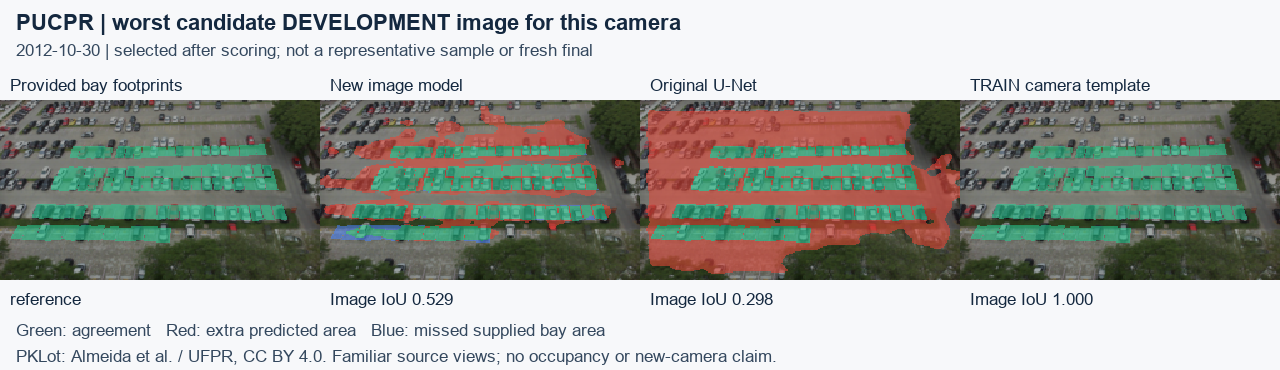

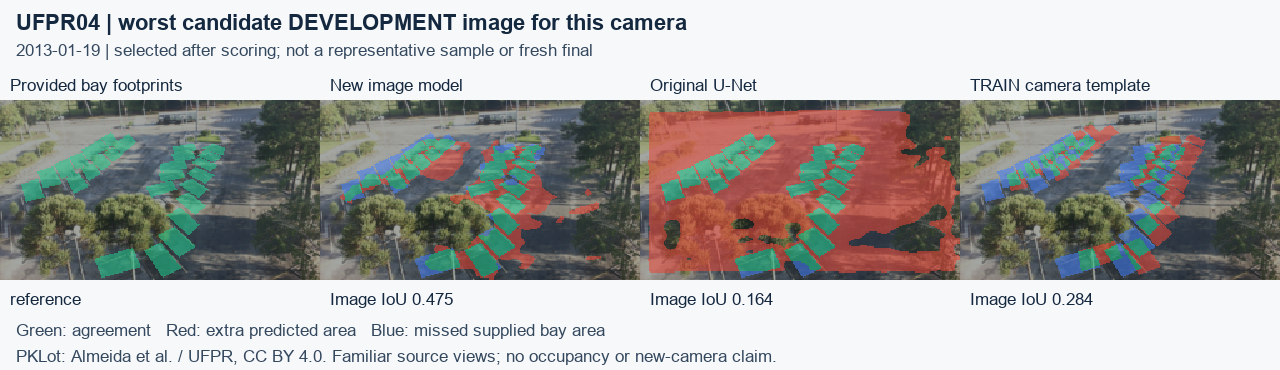

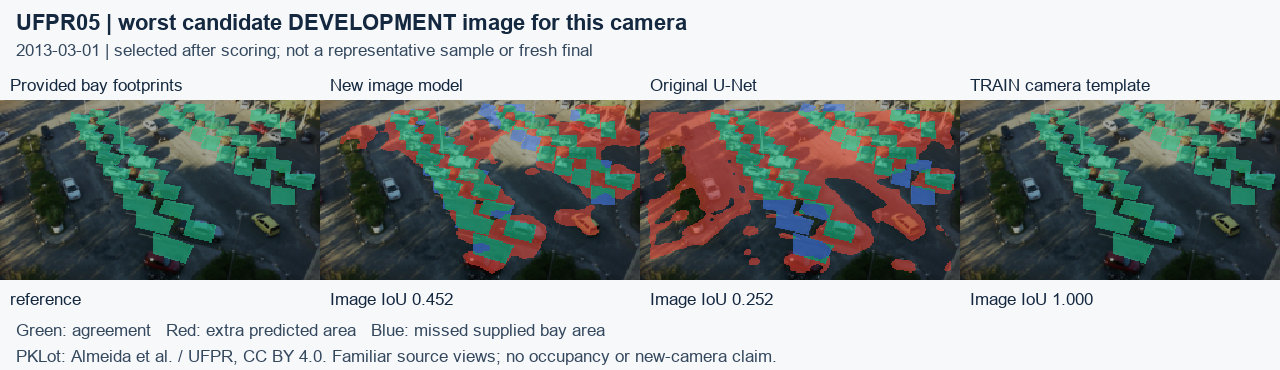

Worst candidate example per camera, selected after scoring; not representative or final.


In [4]:
for camera in ['pucpr','ufpr04','ufpr05']:
    display(Image(filename=str(ROOT/'reports/region_fpn_REGION-FPN-V1-20261027T061402381508Z'/(camera+'_worst_development.png'))))
print('Worst candidate example per camera, selected after scoring; not representative or final.')

Green marks agreement, red extra predicted area,
and blue missed supplied bay area. Unannotated parking regions are not exhaustive
negative ground truth. Four gates failed: meanIoU0.80, each-camera0.75,
each-image0.65, and no camera regression beyond0.05 from the TRAIN template.
Improvement over the original alone is insufficient. No gate was relaxed.
All consumed/quarantined/fresh-final boundaries remain protected.

In [5]:
# SYNTHETIC teaching fixture; not a real image or an extra experiment.
truth={(0,0),(0,1)}
prediction={(0,0),(1,1)}
intersection=len(truth & prediction);union=len(truth | prediction)
iou=intersection/union;dice=2*intersection/(len(truth)+len(prediction))
assert iou==1/3 and dice==.5
print('Synthetic IoU:',iou,'Synthetic Dice:',dice)

Synthetic IoU: 0.3333333333333333 Synthetic Dice: 0.5


In [6]:
checks=dict(archived_inputs=len(manifest['inputs']),images=30,cameras=3,
    failed_gates=sum(not value for value in result['gates'].values()),
    new_model_calls=0,raw_or_final_reads=0,training=False,app_promoted=False,student_mastery_assessed=False)
assert checks['archived_inputs']==6 and checks['failed_gates']==4
print('REGION_LESSON_CHECKS='+json.dumps(checks))

REGION_LESSON_CHECKS={"archived_inputs": 6, "images": 30, "cameras": 3, "failed_gates": 4, "new_model_calls": 0, "raw_or_final_reads": 0, "training": false, "app_promoted": false, "student_mastery_assessed": false}


## Explain this yourself

1. Compute the difference between the new and original mean IoU. Why does it not
   authorize app promotion?
2. Why do equal-camera and image-weighted averages differ?
3. How can a TRAIN-only template score1.0 without understanding an image?
4. Why can the same camera require different layout geometry?
5. Why are the worst examples useful but not a representative sample?
6. What fresh source/split evidence is required before a final reliability claim?

Independent answers and manual presentation remain necessary. Successful code
execution alone does not assess student mastery. Longer, view-balanced training
is a future hypothesis; its recipe and gates must be sealed before fitting.